In [1]:
import numpy as np

from particle_filter.models.noise import GaussianNoise
from particle_filter.models.transition import AdditiveTransitionModel
from particle_filter.models.observation import AdditiveObservationModel

from particle_filter.simulations import system_simulation

from particle_filter.plots.plot_results import plot_results
from particle_filter.plots.plot_comparisons import plot_comparisons
from particle_filter.plots.plot_EES import plot_ESS

from particle_filter.performance_metrics import RMSE, Interval_cover

Ahora se quiere comparar el Bootstrap Particle Filter y el Auxiliary Particle Filter mediante un sistema no lineal.

El sistema es el siguiente:

- Ecuación estado:

$$
x_t = 0.5 \cdot x_{t-1} + \frac{25\cdot x_{t-1}}{1+x_{t-1}^2}+ w_t,\;\;\; w_t \sim \mathcal{N}(0, Q)
$$

- Ecuación de observación

$$
y_t = x_t + 0.05\cdot x_t^{2} + v_t,\;\;\; v_t \sim \mathcal{N}(0, R)
$$

### 1. Variación del ruido de transición
En este primer apartado se deja fijo la matriz de covarianza de la ecuación de observación y se varía el valor de la matriz de covarianza del ruido de transición. La idea es observar si la influencia de tener una ecuación de transición que se va volviendo más incierta, implica un mejor rendimiento del Auxiliary Particle Filter (que hace uso de la observación) respecto al Bootstrap Particle Filter. Dado que se parte de la suposición de que el rendimiento de los dos filtros se iguala cuando el número de partículas es alto, se va a dejar el número de partículas en $N=100$. Otra parametrización que se realiza es que el paso de remuestreo se realiza siempre que el número efectivo de partículas sea inferior al número de partículas, es decir, que 1000.

In [2]:
# Funcion de transicion y observación

def f(x):
    return (
        0.5 * x +
        25*x / (1 + x**2)
    )


def h(x):
    return x + 0.05 * (x ** 2)

In [4]:
# Definición del modelo de transición (fijo)
R = np.array([[1.]])

noise_observation = GaussianNoise(R)
observation = AdditiveObservationModel(h, noise_observation)

In [5]:
import numpy as np
from exp1 import experiment1

T = 100
x0 = np.array([0.0])
Q = [2.0]
N = 100

n_simulations = 10
n_runs = 10

results_bpf, results_apf = experiment1(T, x0, Q, N, n_simulations, n_runs, f, observation, "_2")

Matriz 2.0 finalizado


In [40]:
# Importar resultados
import pickle

with open('results_bpf_exp1.pkl', 'rb') as file:
    results_bpf = pickle.load(file)

with open('results_apf_exp1.pkl', 'rb') as file:
    results_apf = pickle.load(file)

In [27]:
import numpy as np
from functions_experiment1 import calculate_rmse, calculate_loglikelihood, calculate_mean_ess, calculate_mean_IC
from particle_filter.plots.plot_comparisons import plot_comparisons

(<Figure size 800x600 with 1 Axes>,
 <Axes: xlabel='Matriz de covarianza Q', ylabel='RMSE'>)

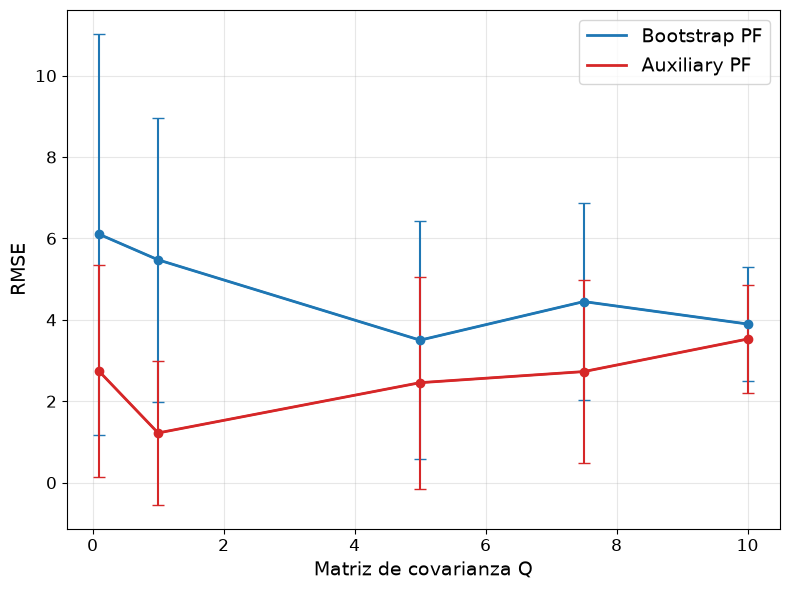

In [41]:
Q = [0.1, 1.0, 5.0, 7.5, 10.0]

rmse_bpf, rmse_bpf_sim = calculate_rmse(results_bpf)
rmse_apf, rmse_apf_sim = calculate_rmse(results_apf)

# Media de 'n_simulations' para cada q
res_rmse_bpf = [ np.mean(rmse_bpf_sim[q]) for q in Q]
res_rmse_apf = [ np.mean(rmse_apf_sim[q]) for q in Q]

# STD para cada q
std_rmse_bpf = [np.std(rmse_bpf_sim[q], ddof=1) for q in Q]
std_rmse_apf = [np.std(rmse_apf_sim[q], ddof=1) for q in Q]

plot_comparisons(
    {
        "Bootstrap PF": { "Matriz de covarianza Q": Q, "RMSE": res_rmse_bpf, "RMSE_errorbars": std_rmse_bpf }, 
        "Auxiliary PF": { "Matriz de covarianza Q": Q, "RMSE": res_rmse_apf, "RMSE_errorbars": std_rmse_apf }, 
    }, "Matriz de covarianza Q", "RMSE", "Comparación del RMSE según la matriz de covarianza Q", True
)

En términos del RMSE, el APF obtiene un error inferior al BPF para todos los valores de Q analizados. La diferencia es especialmente notable para Q = 1.0, donde el RMSE pasa de 5.47 en el BPF a 1.22 en el APF. Para Q = 0.1 el APF presenta un RMSE de 2.73, frente al 6.10 del BPF. Para valores elevados de Q, la diferencia entre ambos métodos es mucho menor, aunque el APF continúa proporcionando una estimación un poco más precisa.    

(<Figure size 800x600 with 1 Axes>,
 <Axes: xlabel='Matriz de covarianza Q', ylabel='Loglikelihood'>)

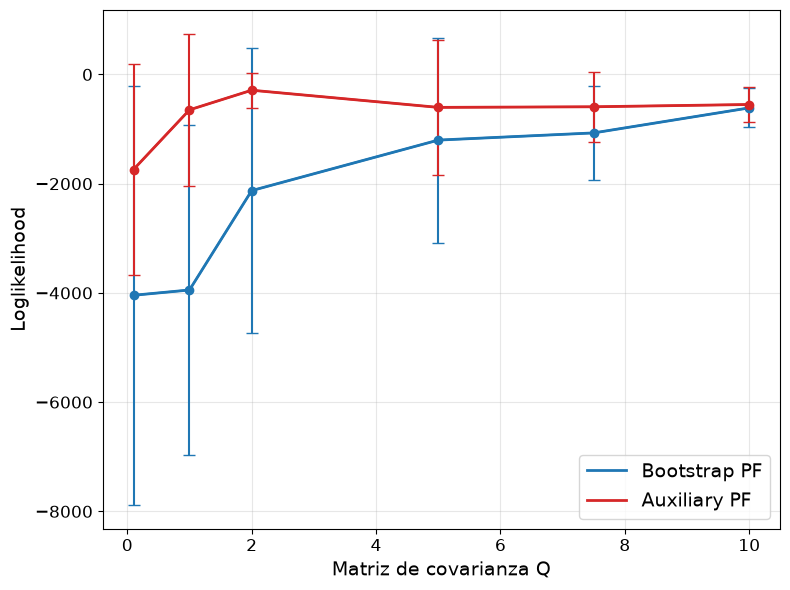

In [ ]:
Q = [0.1, 1.0, 5.0, 7.5, 10.0]

loglikelihood_bpf, loglikelihood_bpf_sim = calculate_loglikelihood(results_bpf)
loglikelihood_apf, loglikelihood_apf_sim = calculate_loglikelihood(results_apf)

# Media para cada q
res_loglikelihood_bpf = [ np.mean(loglikelihood_bpf_sim[q]) for q in Q]
res_loglikelihood_apf = [ np.mean(loglikelihood_apf_sim[q]) for q in Q]

# STD para cada q
std_loglikelihood_bpf = [np.std(loglikelihood_bpf_sim[q], ddof=1) for q in Q]
std_loglikelihood_apf = [np.std(loglikelihood_apf_sim[q], ddof=1) for q in Q]

plot_comparisons(
    {
        "Bootstrap PF": { "Matriz de covarianza Q": Q, "Loglikelihood": res_loglikelihood_bpf, "Loglikelihood_errorbars": std_loglikelihood_bpf }, 
        "Auxiliary PF": { "Matriz de covarianza Q": Q, "Loglikelihood": res_loglikelihood_apf, "Loglikelihood_errorbars": std_loglikelihood_apf}, 
    }, "Matriz de covarianza Q", "Loglikelihood", "Compartación de la log-verosimilitud según la matriz de covarianza Q", True
)

In [39]:
print(res_loglikelihood_apf)
print(std_loglikelihood_apf)

[np.float64(-288.8229380524363)]
[np.float64(317.6001403226873)]


La log-verosimilitud estimada muestra la superioridad general del APF. Para todos los valores de Q, el APF obtiene mayores valores, siendo la diferencia especialmente elevada para Q = 0.1 y Q = 1.0. A medida que aumenta Q, la diferencia entre ambos se reduce, alcanzándose valores próximos para Q =10. 

(<Figure size 800x600 with 1 Axes>,
 <Axes: title={'center': 'Comparación del número efectivo de partículas'}, xlabel='Q', ylabel='ESS/N'>)

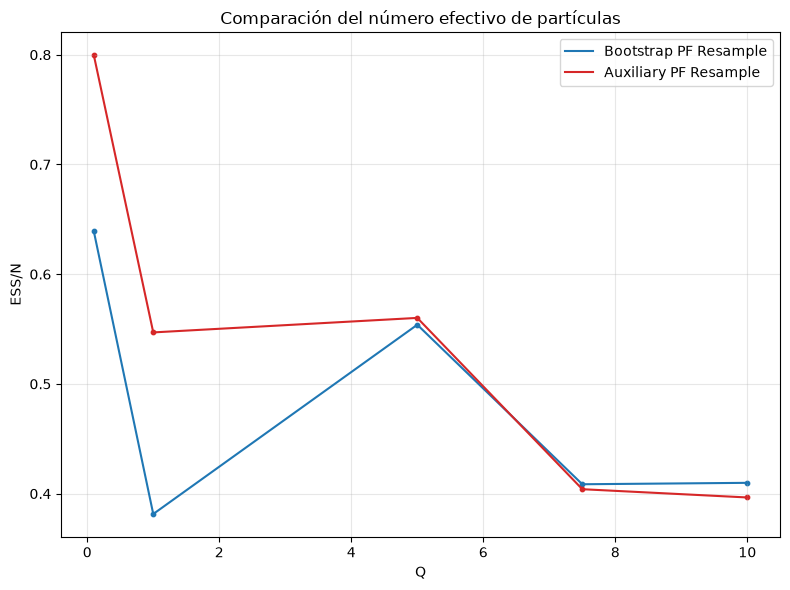

In [13]:
ess_bpf = calculate_mean_ess(results_bpf)
ess_apf = calculate_mean_ess(results_apf)

# Media para cada q
res_ess_bpf = [ np.mean(ess_bpf[q]) for q in Q]
res_ess_apf = [ np.mean(ess_apf[q]) for q in Q]

# STD para cada q
std_ess_bpf = [np.std(ess_bpf[q], ddof=1) for q in Q]
std_ess_apf = [np.std(ess_bpf[q], ddof=1) for q in Q]

plot_comparisons(
    {
        "Bootstrap PF Resample": { "Q": Q, "ESS/N": res_ess_bpf, "ESS/N_errorbars": std_ess_bpf }, 
        "Auxiliary PF Resample": { "Q": Q, "ESS/N": res_ess_apf, "ESS/N_errorbars": std_ess_apf }, 
    }, "Q", "ESS/N", "Comparación del número efectivo de partículas", False
)

En cuanto al número efectivo de partículas, la gráfica refleja los resultados tras el paso de actualización. En el experimento siempre se ha realizado remuestreo después. 

El comportamiento muestra ventaja en el ESS normalizado para valores bajos de Q. Para Q=0.1, el APF alcanza un ESS/N de 0.80, mientras en el BPF es 0.64; mientras que para el Q=1.0, los valores son 0.55 y 0.38. Sin embargo, para valores elevados de Q, la diferencia prácticamente desaparece e incluso el BPF presenta valores superiores. Esto indica que un ESS elevado no implica necesariamente una menor incertidumbre de estimación ni un menor RMSE. La inflcuencia de este parámetro se estudiará en el tercer apartado.

(<Figure size 800x600 with 1 Axes>,
 <Axes: title={'center': 'Comparación del porcentaje de estados dentro del intervalo de credibilidad'}, xlabel='Q', ylabel='IC'>)

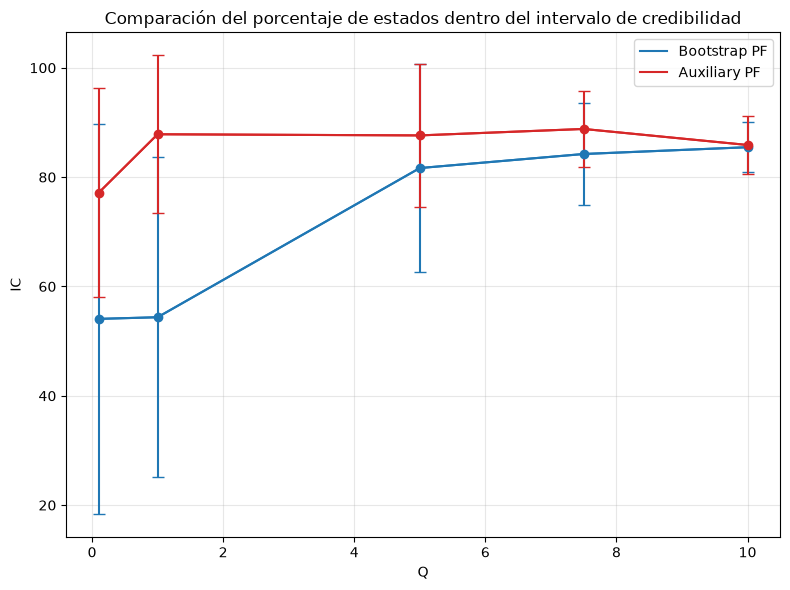

In [15]:
IC_bpf, IC_bpf_sim = calculate_mean_IC(results_bpf, Interval_cover)
IC_apf, IC_apf_sim = calculate_mean_IC(results_apf, Interval_cover)

# Media para cada q
res_IC_bpf = [ np.mean(IC_bpf_sim[q]) for q in Q]
res_IC_apf = [ np.mean(IC_apf_sim[q]) for q in Q]

# STD para cada q
std_IC_bpf = [np.std(IC_bpf_sim[q], ddof=1) for q in Q]
std_IC_apf = [np.std(IC_apf_sim[q], ddof=1) for q in Q]

plot_comparisons(
    {
        "Bootstrap PF": { "Q": Q, "IC": res_IC_bpf, "IC_errorbars": std_IC_bpf }, 
        "Auxiliary PF": { "Q": Q, "IC": res_IC_apf, "IC_errorbars": std_IC_apf }, 
    }, "Q", "IC", "Comparación del porcentaje de estados dentro del intervalo de credibilidad",True
)

Finalmente, los intervalos de cobertura del 95%, muestra que el APF proporciona intervalos mejor calibrados que el BPF, especialmente para valores bajos de Q. Para valores elevados de Q, ambos filtros presentan cobertura similares, próximas al 89%. No obstante, ninguno de los dos métodos alcanza de forma consistente la cobertura teórcia del 95%.  

Por último, se va a representar el número efectivo de partículas en función del tiempo de simulación.

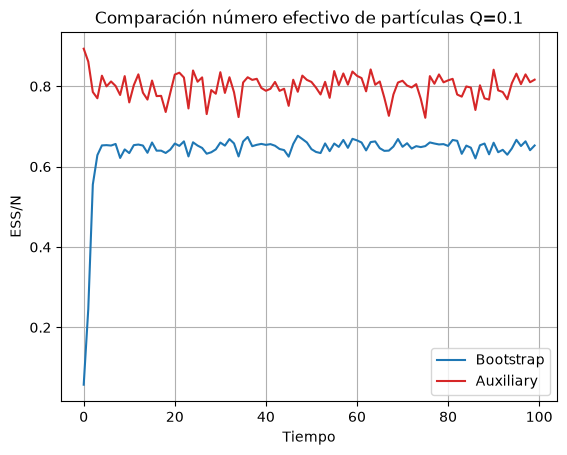

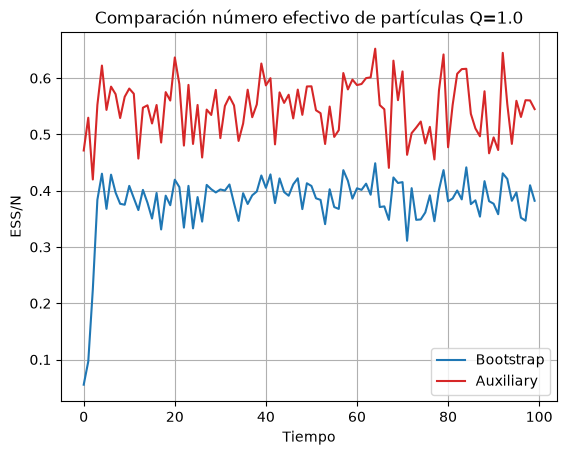

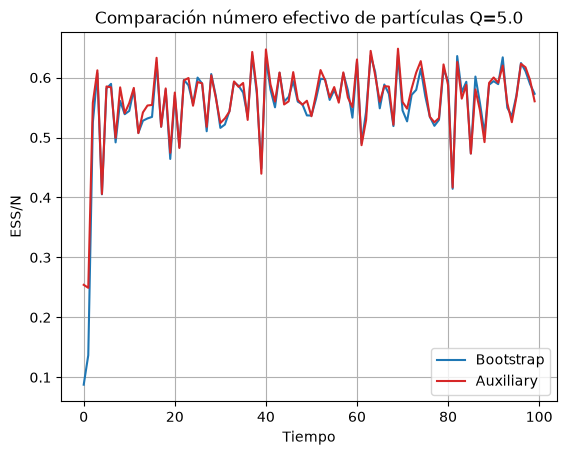

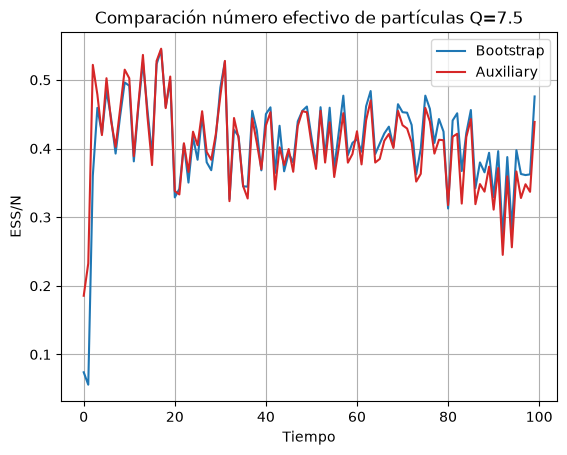

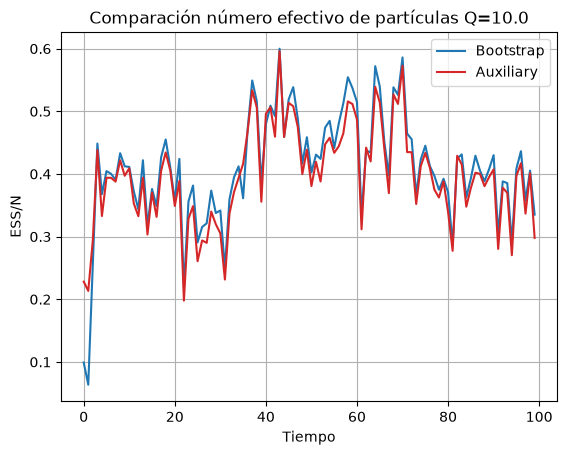

In [17]:
from functions_experiment1 import ESS_weights_mean_in_time
import matplotlib.pyplot as plt
import numpy as np

N_simul = 10
N_run = 10
T = 100
N_parts = 100

_, mean_ess_time_bpf = ESS_weights_mean_in_time(results_bpf, N_simul, N_run, T, N_parts)
_, mean_ess_time_apf = ESS_weights_mean_in_time(results_apf, N_simul, N_run, T, N_parts)

plt.plot(figsize=(8,6))

Q = [0.1, 1.0, 5.0, 7.5, 10.0]

for q in Q: 
    plt.plot(np.arange(T), mean_ess_time_bpf[q]["mean"], color="tab:blue", ls="-", label=f"Bootstrap")
    plt.plot(np.arange(T), mean_ess_time_apf[q]["mean"], color="tab:red", ls="-", label=f"Auxiliary")

    plt.xlabel("Tiempo")
    plt.ylabel("ESS/N")

    plt.title(f"Comparación número efectivo de partículas Q={q}")

    plt.grid(True)
    
    plt.legend()
    plt.show()

En estas últimas gráficas se aprecia cómo el número efectivo de partículas es superior en el caso del APF para los dos primeros valores del ruido de proceso. A medida que este aumenta, las cantidades se van igualando.

En conjunto, los resultados sugieren que el APF aprovecha mejor la información proporcionada por las observación actual para realizar la selección de partículas, lo que se traduce en mejores resultado cuando Q es pequeño o moderado. En estos casos, la información del estado anterior $x_{t-1}$, combinada con $y_t$ permite identificar mejor qué partículas tienen probabilidades de conducir a estados compatibles con la nueva observación. Sin embargo, cuando el ruido del proceso aumenta, la ventaja del APF disminuye y ambos filtros presentan un comportamiento similar. Esto puede deberse a que un incremento de Q aumenta la dispersión de la distriución de transición, por lo que la capacidad del APF para anticipar qué serán buenas partículas antes de la propagación se vuelve menos efectiva.

### 2. Variación del número de partículas

Ahora se va a tomar el caso en el que $Q=1.0$ y $R=1.0$ y se va a modificar el número de partículas. En ambos casos el criterio de remustreo es el mismo que en la sección anterior.

In [3]:
from exp2 import experiment2

# Longitud de la simulacion
T = 100

# Estado inicial
x0 = np.array([[0.0]])

# Valores para el número de partículas
N = [25, 50, 100, 250, 500, 1000]

# Numero de simulaciones
n_simulations = 10

# Numero ejecuciones filtro
n_runs = 10

#--------------------------------------
# MODELOS DE TRANSICION Y OBSERVACION
#--------------------------------------
Q = np.array([10.0]) 

R = np.array([[1.]])

noise_transition = GaussianNoise(Q)
transition = AdditiveTransitionModel(f, noise_transition)

noise_observation = GaussianNoise(R)
observation = AdditiveObservationModel(h, noise_observation)

results_bpf, results_apf = experiment2(T, x0, N, n_simulations, n_runs, transition, observation, "_3")


Matriz 25 finalizado
Matriz 50 finalizado
Matriz 100 finalizado
Matriz 250 finalizado
Matriz 500 finalizado
Matriz 1000 finalizado


In [53]:
# Importar resultados
import numpy as np
import pickle

with open('results_bpf_exp2_2.pkl', 'rb') as file:
    results_bpf = pickle.load(file)

with open('results_apf_exp2_2.pkl', 'rb') as file:
    results_apf = pickle.load(file)

In [45]:
from functions_experiment2 import calculate_rmse, calculate_loglikelihood, calculate_mean_ess, calculate_mean_IC, calculate_execution_time

In [46]:
N = [25, 50, 100, 250, 500, 1000]

(<Figure size 800x600 with 1 Axes>,
 <Axes: xlabel='Número de partículas N', ylabel='RMSE'>)

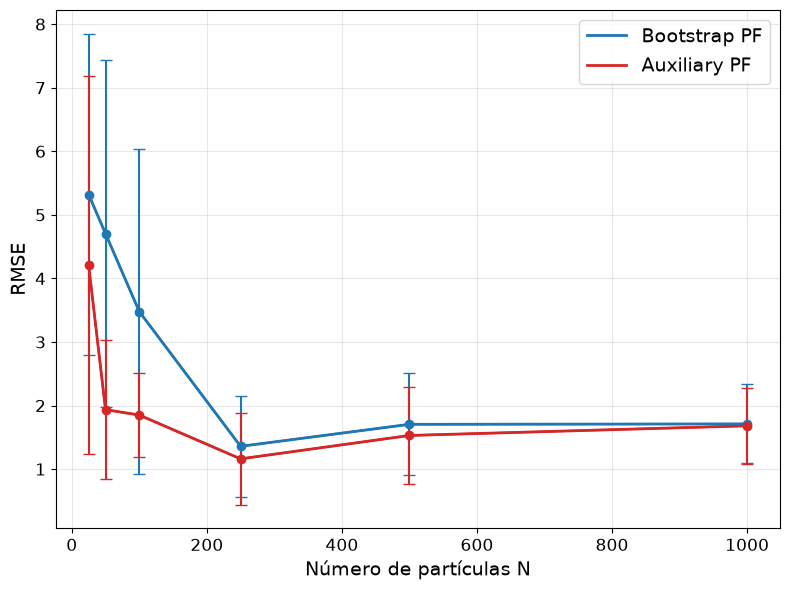

In [54]:
rmse_bpf, rmse_bpf_sim = calculate_rmse(results_bpf)
rmse_apf, rmse_apf_sim = calculate_rmse(results_apf)

# Media de 'n_simulations' para cada n
res_rmse_bpf = [ np.mean(rmse_bpf_sim[n]) for n in N]
res_rmse_apf = [ np.mean(rmse_apf_sim[n]) for n in N]

# STD para cada q
std_rmse_bpf = [np.std(rmse_bpf_sim[n], ddof=1) for n in N]
std_rmse_apf = [np.std(rmse_apf_sim[n], ddof=1) for n in N]

plot_comparisons(
    {
        "Bootstrap PF": { "Número de partículas N": N, "RMSE": res_rmse_bpf, "RMSE_errorbars": std_rmse_bpf }, 
        "Auxiliary PF": { "Número de partículas N": N, "RMSE": res_rmse_apf, "RMSE_errorbars": std_rmse_apf }, 
    }, "Número de partículas N", "RMSE", "Comparación del RMSE según el número de partículas", True
)

A medida que el número de partículas aumenta, el RMSE tiene en general hacia la reducción del error, aunque esta reducción no es monótona debido a la variabilidad de los métodos de Monte Carlo.

Para el BPF se observa una reducción especialmente importante para N=250. En el APF, se tiene un clara ventaja para N=100 y N=250 frente al BPF. Para N=500 y N=1000, ambos métodos presentan resultados muy similares. Cuando el número de partículas es elevado, la ventaja proporcionada por el APF disminuye.

Las desviaciones estándar presentan una diferencia notable para N=50 y N=100 donde el APF muestra valores más estables respecto al BPF.

(<Figure size 800x600 with 1 Axes>,
 <Axes: xlabel='Número de partículas N', ylabel='Loglikelihood'>)

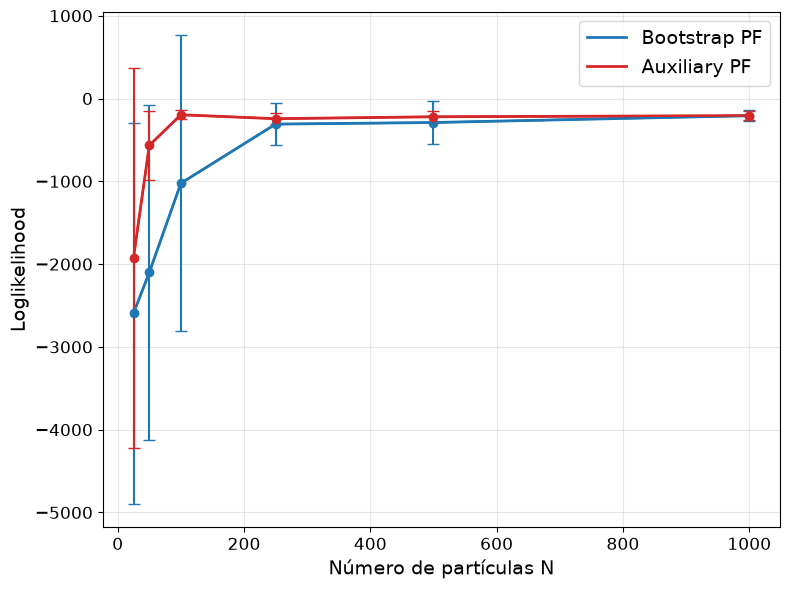

In [55]:
loglikelihood_bpf, loglikelihood_bpf_sim = calculate_loglikelihood(results_bpf)
loglikelihood_apf, loglikelihood_apf_sim = calculate_loglikelihood(results_apf)

# Media para cada q
res_loglikelihood_bpf = [ np.mean(loglikelihood_bpf_sim[n]) for n in N]
res_loglikelihood_apf = [ np.mean(loglikelihood_apf_sim[n]) for n in N]

# STD para cada q
std_loglikelihood_bpf = [np.std(loglikelihood_bpf_sim[n], ddof=1) for n in N]
std_loglikelihood_apf = [np.std(loglikelihood_apf_sim[n], ddof=1) for n in N]

plot_comparisons(
    {
        "Bootstrap PF": { "Número de partículas N": N, "Loglikelihood": res_loglikelihood_bpf, "Loglikelihood_errorbars": std_loglikelihood_bpf }, 
        "Auxiliary PF": { "Número de partículas N": N, "Loglikelihood": res_loglikelihood_apf, "Loglikelihood_errorbars": std_loglikelihood_apf}, 
    }, "Número de partículas N", "Loglikelihood", "Comparación del la log-verosimilitud según el número de partículas", True
)

(<Figure size 800x600 with 1 Axes>,
 <Axes: xlabel='Número de partículas N', ylabel='Tiempo de ejecución (s)'>)

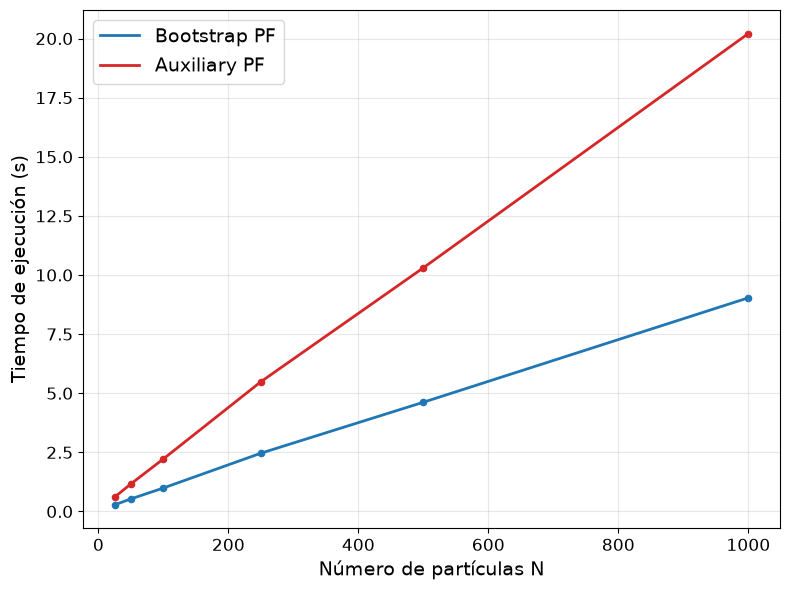

In [12]:
time_execution_bpf, time_execution_bpf_sim = calculate_execution_time(results_bpf)
time_execution_apf, time_execution_apf_sim = calculate_execution_time(results_apf)

# Media para cada q
res_time_execution_bpf = [ np.mean(time_execution_bpf_sim[n]) for n in N]
res_time_execution_apf = [ np.mean(time_execution_apf_sim[n]) for n in N]

# STD para cada q
std_time_execution_bpf = [np.std(time_execution_bpf_sim[n], ddof=1) for n in N]
std_time_execution_apf = [np.std(time_execution_apf_sim[n], ddof=1) for n in N]

plot_comparisons(
    {
        "Bootstrap PF": { "Número de partículas N": N, "Tiempo de ejecución (s)": res_time_execution_bpf, "Tiempo de ejecución (s)_errorbars": std_time_execution_bpf }, 
        "Auxiliary PF": { "Número de partículas N": N, "Tiempo de ejecución (s)": res_time_execution_apf, "Tiempo de ejecución (s)_errorbars": std_time_execution_apf}, 
    }, "Número de partículas N", "Tiempo de ejecución (s)", "Comparación del tiempo de ejecución según el número de partículas", False
)

La log-verosimilitud presenta un comportamiento similar al RMSE. Para valores pequeños de N, se tiene un mejor rendimiento para el APF, siendo la diferencia notable para N=100. A partir de N=500, ambos métodos presentan valores muy próximos. La desviación estandar disminuye considerablemente al aumentar el número de partículas, siendo especialmente significativa la reducción para el APF a partir de N=100.

(<Figure size 800x600 with 1 Axes>,
 <Axes: title={'center': 'Comparación del número efectivo de partículas'}, xlabel='N', ylabel='ESS/N'>)

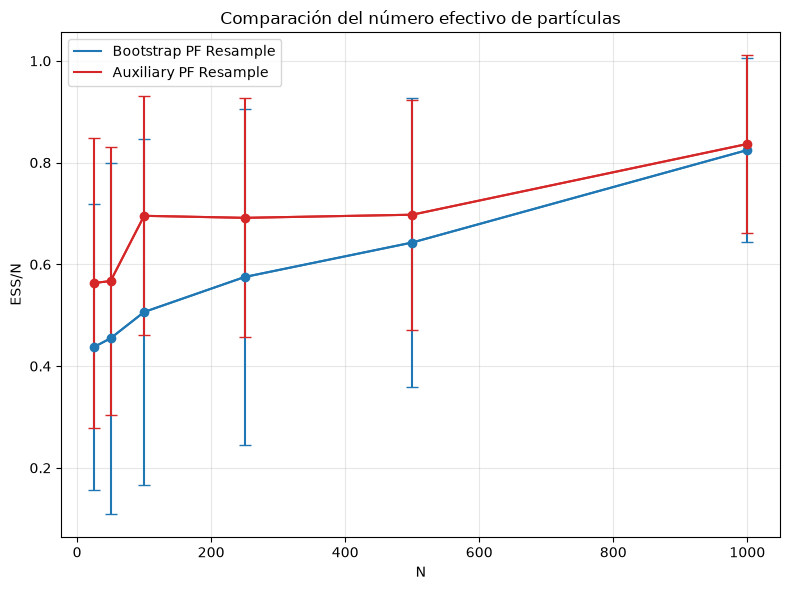

In [18]:
ess_bpf = calculate_mean_ess(results_bpf)
ess_apf = calculate_mean_ess(results_apf)

# Media para cada q
res_ess_bpf = [ np.mean(ess_bpf[n]) for n in N]
res_ess_apf = [ np.mean(ess_apf[n]) for n in N]

# STD para cada q
std_ess_bpf = [np.std(ess_bpf[n], ddof=1) for n in N]
std_ess_apf = [np.std(ess_apf[n], ddof=1) for n in N]

plot_comparisons(
    {
        "Bootstrap PF Resample": { "N": N, "ESS/N": res_ess_bpf, "ESS/N_errorbars": std_ess_bpf }, 
        "Auxiliary PF Resample": { "N": N, "ESS/N": res_ess_apf, "ESS/N_errorbars": std_ess_apf }, 
    }, "N", "ESS/N", "Comparación del número efectivo de partículas", True
)

(<Figure size 800x600 with 1 Axes>,
 <Axes: title={'center': 'Comparación del Intervalo de Confianza'}, xlabel='N', ylabel='IC'>)

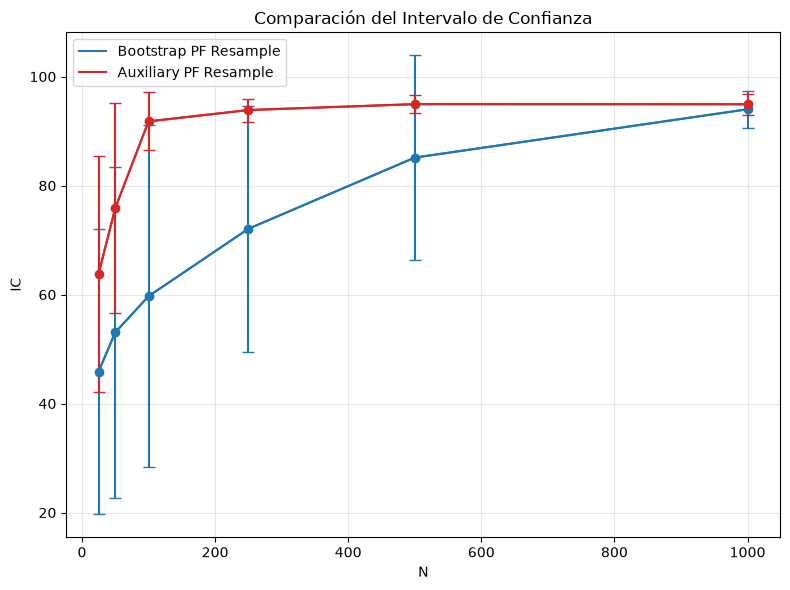

In [16]:
IC_bpf, IC_bpf_sim = calculate_mean_IC(results_bpf, Interval_cover)
IC_apf, IC_apf_sim = calculate_mean_IC(results_apf, Interval_cover)

# Media para cada q
res_IC_bpf = [ np.mean(IC_bpf_sim[n]) for n in N]
res_IC_apf = [ np.mean(IC_apf_sim[n]) for n in N]

# STD para cada q
std_IC_bpf = [np.std(IC_bpf_sim[n], ddof=1) for n in N]
std_IC_apf = [np.std(IC_apf_sim[n], ddof=1) for n in N]

plot_comparisons(
    {
        "Bootstrap PF Resample": { "N": N, "IC": res_IC_bpf, "IC_errorbars": std_IC_bpf }, 
        "Auxiliary PF Resample": { "N": N, "IC": res_IC_apf, "IC_errorbars": std_IC_apf }, 
    }, "N", "IC", "Comparación del Intervalo de Confianza", True
)

La cobertura de los intervalos presenta una tendencia creciente con el númerode partículas, especialmente para el BPF. De manera similar a las anteriores métricas, el APF presenta ventaja para valores pequeños de N, pero a partir de N=500 las coberturas son similares y próximas al valor teórico del 95%. De nuevo, las desviaciones estándar disminuyen de forma significativa a medida que aumenta el número de partículas. Esto indica que el incremento de N no sol mejora la cobertura media, sino que también reduce su variabilidad entre ejecuciones.

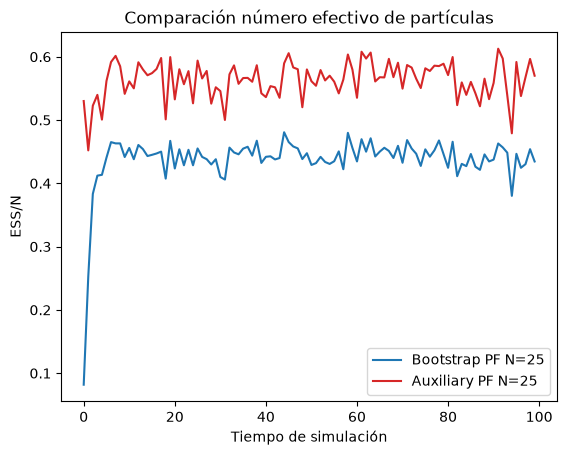

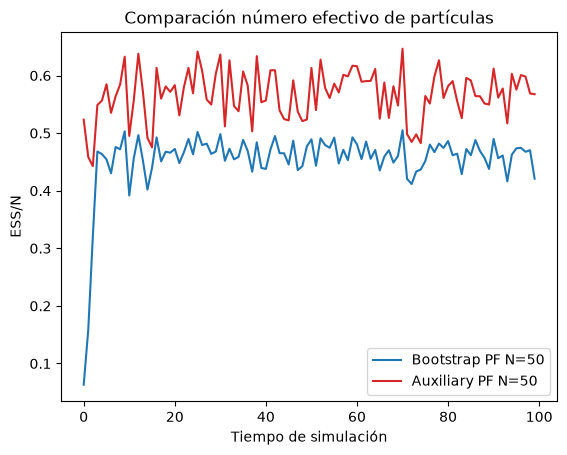

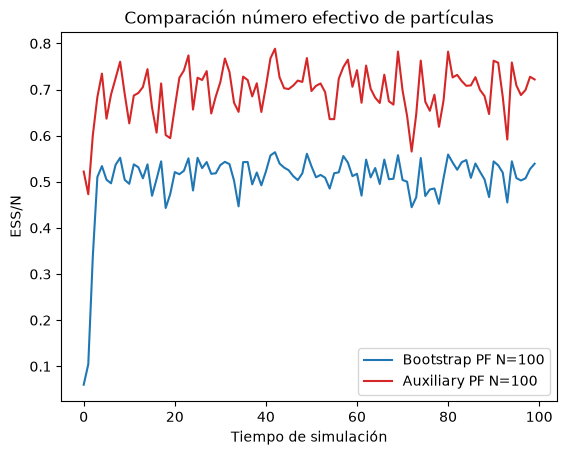

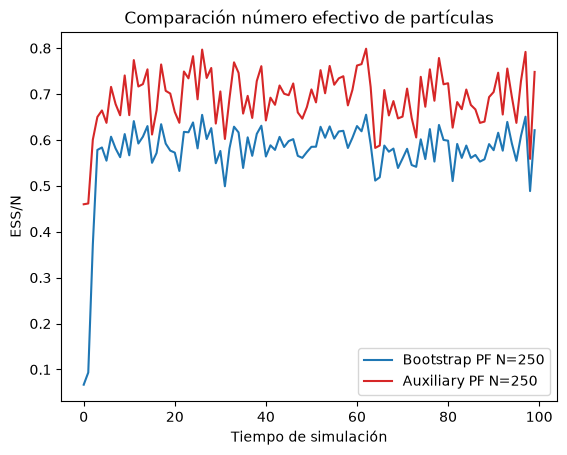

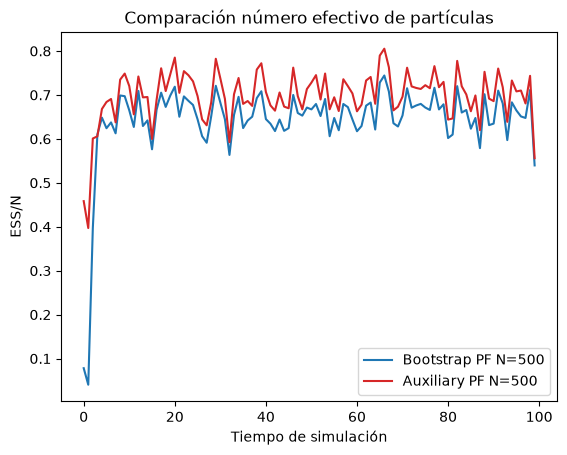

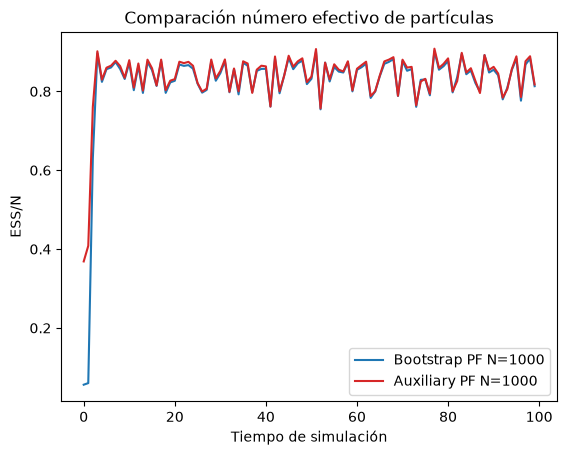

In [19]:
from functions_experiment2 import ESS_weights_mean_in_time2
import matplotlib.pyplot as plt
import numpy as np

N_simul = 10
N_run = 10
T = 100

_, mean_ess_time_bpf = ESS_weights_mean_in_time2(results_bpf, N_simul, N_run, T)
_, mean_ess_time_apf = ESS_weights_mean_in_time2(results_apf, N_simul, N_run, T)

plt.plot(figsize=(8,6))

N = [25, 50, 100, 250, 500, 1000]

for n in N: 
    plt.plot(np.arange(T), mean_ess_time_bpf[n]["mean"], color="tab:blue", ls="-", label=f"Bootstrap PF N={n}")
    plt.plot(np.arange(T), mean_ess_time_apf[n]["mean"], color="tab:red", ls="-", label=f"Auxiliary PF N={n}")

    plt.xlabel("Tiempo de simulación")
    plt.ylabel("ESS/N")
    plt.title("Comparación número efectivo de partículas")

    plt.legend()
    plt.show()

El resultado sugiere que la principal ventaja del APF aparece cuando el número de partículas es limitado. Con pocas partículas, el BPF puede desperdiciar una parte importante en regiones del espacio de estados que tienen poca probabilidad de explicar la observación actual. El APF, mediante su mecanismo auxiliar, utiliza la información de la observación para realizar una selección más informada antes de la propagación.

Cuando se llega a $N=1000$, el BPF dispone de tantas partículas que resulta mucho menos probable que la representación de la distribución sea deficiente.